In [1]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.style.use("default")
sns.set_theme(style="whitegrid")

%run 00.ipynb

c:\Users\SafinSharma\miniconda3\envs\forecasting\Lib\site-packages\nbformat\__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


Export Folder : standardized_exports
Results Folder: results
24
Datasets Found: 22
agri_medium
agri_small
energy_medium
energy_small
favorita-train_medium
favorita-train_medium_cov
favorita-train_small
favorita-train_small_cov
favorita-transaction_medium
favorita-transaction_small
m4-daily_medium
m4-daily_small
m4-hourly_medium
m4-hourly_small
m4-quarterly_medium
m4-quarterly_small
m4-weekly_medium
m4-weekly_small
m4-yearly_medium
m4-yearly_small
traffic_medium
traffic_small
5
agri_medium               rows=15343      series=246      horizon=5
5
agri_small                rows=14428      series=246      horizon=5
24
energy_medium             rows=177600     series=370      horizon=24
24
energy_small              rows=44400      series=370      horizon=24
28
favorita-train_medium     rows=1985155    series=4504     horizon=28
favorita-train_medium_cov -> ERROR: No horizon configured for favorita-train_medium_cov
28
favorita-train_small      rows=609961     series=4504     horizon=28
favo

In [2]:
CLASSICAL_FILE = (
    RESULTS_FOLDER /
    "classical_results.csv"
)

ML_FILE = (
    RESULTS_FOLDER /
    "ml_results.csv"
)

DL_FILE = (
    RESULTS_FOLDER /
    "dl_results.csv"
)

FOUNDATION_FILE = (
    RESULTS_FOLDER /
    "foundation_results.csv"
)

frames = []

for file in [
    CLASSICAL_FILE,
    ML_FILE,
    DL_FILE,
    FOUNDATION_FILE
]:

    if file.exists():

        df = pd.read_csv(file)

        frames.append(df)

all_results = pd.concat(
    frames,
    ignore_index=True
)

print(all_results.shape)

all_results.head()

(145, 9)


,model,dataset,n_series,n_rows,horizon,runtime_seconds,MAE,RMSE,SMAPE
0,Naive,agri_medium,246,15343,5,1.266055,590406.644935,3.723966e+06,10.800519
1,SeasonalNaive,agri_medium,246,15343,5,1.435681,590406.644935,3.723966e+06,10.800519
2,ARIMA,agri_medium,246,15343,5,13.942256,214449.339510,6.649463e+05,9.278785
3,SARIMA,agri_medium,246,15343,5,0.502644,204309.587000,6.231367e+05,9.294803
4,Naive,agri_small,246,14428,5,1.181755,590406.644935,3.723966e+06,10.800519


In [3]:
print(
    all_results.isna().sum()
)

all_results = (
    all_results
    .drop_duplicates()
    .reset_index(drop=True)
)

print(
    all_results["model"]
    .value_counts()
)

model              0
dataset            0
n_series           0
n_rows             0
horizon            0
runtime_seconds    0
MAE                0
RMSE               0
SMAPE              0
dtype: int64
model
Naive            20
SeasonalNaive    20
ARIMA            20
SARIMA           20
TTM              20
LightGBM         16
XGBoost          16
Chronos           8
LSTM              5
Name: count, dtype: int64


In [4]:
overall = (
    all_results
    .groupby("model")
    [
        [
            "MAE",
            "RMSE",
            "SMAPE",
            "runtime_seconds"
        ]
    ]
    .mean()
    .round(4)
)

overall = overall.sort_values(
    "SMAPE"
)

overall

,MAE,RMSE,SMAPE,runtime_seconds
model,,,,
ARIMA,2.176717e+04,6.846919e+04,24.2654,23.8935
Chronos,1.528036e+05,1.043283e+06,24.8993,4553.9464
Naive,5.956931e+04,3.742693e+05,25.5514,564.6595
TTM,5.956931e+04,3.742693e+05,25.5514,154.3657
SeasonalNaive,5.960875e+04,3.742841e+05,26.9122,564.2867
SARIMA,4.582197e+113,2.036474e+115,34.7960,57.9490
LightGBM,1.694952e+05,1.474011e+06,45.3453,87.6497
XGBoost,1.639158e+05,1.481174e+06,46.5343,123.4076
LSTM,2.334555e+06,1.286872e+07,121.1512,6214.7064


In [5]:
overall.to_csv(
    RESULTS_FOLDER /
    "overall_model_summary.csv"
)

overall

,MAE,RMSE,SMAPE,runtime_seconds
model,,,,
ARIMA,2.176717e+04,6.846919e+04,24.2654,23.8935
Chronos,1.528036e+05,1.043283e+06,24.8993,4553.9464
Naive,5.956931e+04,3.742693e+05,25.5514,564.6595
TTM,5.956931e+04,3.742693e+05,25.5514,154.3657
SeasonalNaive,5.960875e+04,3.742841e+05,26.9122,564.2867
SARIMA,4.582197e+113,2.036474e+115,34.7960,57.9490
LightGBM,1.694952e+05,1.474011e+06,45.3453,87.6497
XGBoost,1.639158e+05,1.481174e+06,46.5343,123.4076
LSTM,2.334555e+06,1.286872e+07,121.1512,6214.7064


In [6]:
ranking = (
    all_results
    .groupby("dataset")
    .apply(
        lambda x:
        x.sort_values("SMAPE")
        .assign(
            rank=range(
                1,
                len(x)+1
            )
        )
    )
    .reset_index(drop=True)
)

ranking.head()

,model,n_series,n_rows,horizon,runtime_seconds,MAE,RMSE,SMAPE,rank
0,ARIMA,246,15343,5,13.942256,214449.339510,6.649463e+05,9.278785,1
1,SARIMA,246,15343,5,0.502644,204309.587000,6.231367e+05,9.294803,2
2,Naive,246,15343,5,1.266055,590406.644935,3.723966e+06,10.800519,3
3,SeasonalNaive,246,15343,5,1.435681,590406.644935,3.723966e+06,10.800519,4
4,TTM,246,15343,5,0.600201,590406.644935,3.723966e+06,10.800519,5


In [7]:
avg_rank = (
    ranking
    .groupby("model")["rank"]
    .mean()
    .sort_values()
    .round(2)
)

avg_rank

model
ARIMA            2.60
Naive            2.80
SARIMA           3.10
Chronos          3.12
SeasonalNaive    3.95
TTM              4.05
LightGBM         6.75
XGBoost          7.25
LSTM             7.60
Name: rank, dtype: float64

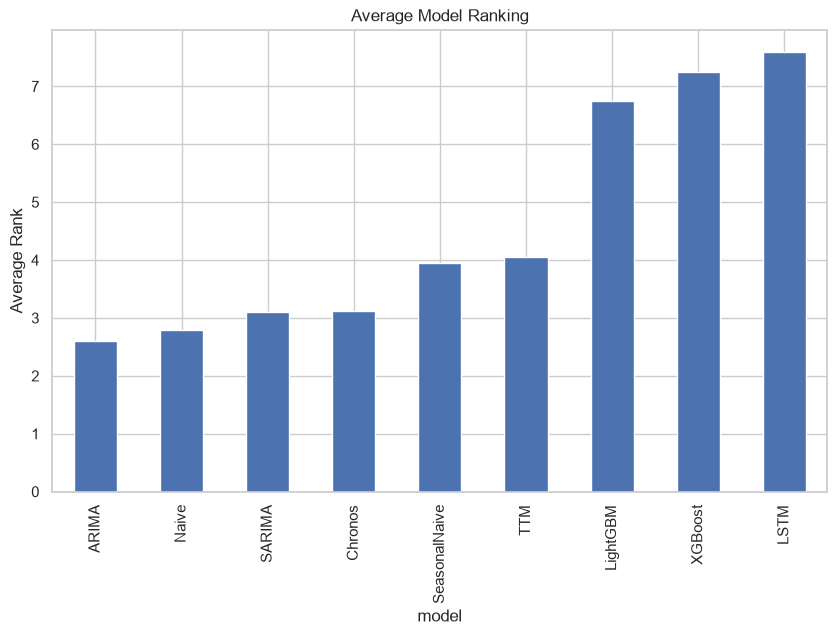

In [8]:
plt.figure(
    figsize=(10,6)
)

avg_rank.plot(
    kind="bar"
)

plt.ylabel(
    "Average Rank"
)

plt.title(
    "Average Model Ranking"
)

plt.show()

In [9]:
overall.head()

,MAE,RMSE,SMAPE,runtime_seconds
model,,,,
ARIMA,21767.1712,6.846919e+04,24.2654,23.8935
Chronos,152803.5878,1.043283e+06,24.8993,4553.9464
Naive,59569.3050,3.742693e+05,25.5514,564.6595
TTM,59569.3050,3.742693e+05,25.5514,154.3657
SeasonalNaive,59608.7479,3.742841e+05,26.9122,564.2867


In [10]:
ranking.head()

,model,n_series,n_rows,horizon,runtime_seconds,MAE,RMSE,SMAPE,rank
0,ARIMA,246,15343,5,13.942256,214449.339510,6.649463e+05,9.278785,1
1,SARIMA,246,15343,5,0.502644,204309.587000,6.231367e+05,9.294803,2
2,Naive,246,15343,5,1.266055,590406.644935,3.723966e+06,10.800519,3
3,SeasonalNaive,246,15343,5,1.435681,590406.644935,3.723966e+06,10.800519,4
4,TTM,246,15343,5,0.600201,590406.644935,3.723966e+06,10.800519,5


In [11]:
best_models = (
    ranking
    .sort_values("rank")
    .groupby("model")
    .first()
    .reset_index()
)

best_models[
    [
        "model",
        "SMAPE"
    ]
]

,model,SMAPE
0,ARIMA,9.278785
1,Chronos,50.690584
2,LSTM,52.514096
3,LightGBM,34.542539
4,Naive,48.494804
5,SARIMA,5.994315
6,SeasonalNaive,48.494804
7,TTM,48.494804
8,XGBoost,12.619025


In [12]:
family_map = {
    "Naive":"Classical",
    "SeasonalNaive":"Classical",
    "ARIMA":"Classical",
    "SARIMA":"Classical",

    "LightGBM":"Machine Learning",
    "XGBoost":"Machine Learning",

    "LSTM":"Deep Learning",
    "NHITS":"Deep Learning",

    "Chronos":"Foundation",
    "TTM":"Foundation"
}

all_results["family"] = (
    all_results["model"]
    .map(family_map)
)

In [13]:
family_results = (
    all_results
    .groupby("family")
    [
        [
            "MAE",
            "RMSE",
            "SMAPE"
        ]
    ]
    .mean()
    .round(4)
)

family_results

,MAE,RMSE,SMAPE
family,,,
Classical,1.145549e+113,5.091185e+114,27.8813
Deep Learning,2.334555e+06,1.286872e+07,121.1512
Foundation,8.620767e+04,5.654160e+05,25.3651
Machine Learning,1.667055e+05,1.477592e+06,45.9398


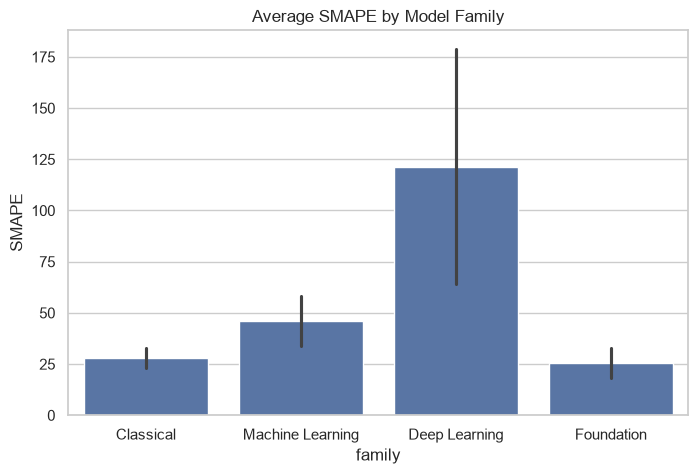

In [14]:
plt.figure(
    figsize=(8,5)
)

sns.barplot(
    data=all_results,
    x="family",
    y="SMAPE",
    estimator=np.mean
)

plt.title(
    "Average SMAPE by Model Family"
)

plt.show()

In [15]:
comparison = (
    all_results
    .groupby(
        [
            "family",
            "model"
        ]
    )["SMAPE"]
    .mean()
    .sort_values()
)

comparison

family            model        
Classical         ARIMA             24.265442
Foundation        Chronos           24.899302
Classical         Naive             25.551445
Foundation        TTM               25.551445
Classical         SeasonalNaive     26.912169
                  SARIMA            34.795985
Machine Learning  LightGBM          45.345277
                  XGBoost           46.534258
Deep Learning     LSTM             121.151188
Name: SMAPE, dtype: float64

In [16]:
foundation_results = all_results[
    all_results["family"] ==
    "Foundation"
]

foundation_results.sort_values(
    "SMAPE"
)

,model,dataset,n_series,n_rows,horizon,runtime_seconds,MAE,RMSE,SMAPE,family
134,TTM,m4-daily_small,4227,295890,20,48.015012,196.037857,6.532346e+02,3.273635,Foundation
133,TTM,m4-daily_medium,4227,1129574,20,43.332872,196.037857,6.532346e+02,3.273635,Foundation
129,Chronos,favorita-transaction_medium,2,1120,28,9.732871,97.876285,1.462934e+02,6.341407,Foundation
131,Chronos,favorita-transaction_small,2,280,28,4.382200,112.955209,1.651777e+02,6.850688,Foundation
130,TTM,favorita-transaction_medium,2,1120,28,0.008084,97.428571,1.237144e+02,6.883313,Foundation
132,TTM,favorita-transaction_small,2,280,28,0.021546,97.428571,1.237144e+02,6.883313,Foundation
140,TTM,m4-weekly_small,359,23335,20,0.715170,322.110404,5.967022e+02,8.607993,Foundation
139,TTM,m4-weekly_medium,359,81627,20,0.970981,322.110404,5.967022e+02,8.607993,Foundation
143,TTM,traffic_medium,207,99360,48,0.270097,4.381174,9.954850e+00,8.769702,Foundation
144,TTM,traffic_small,207,24840,48,0.332371,4.381174,9.954850e+00,8.769702,Foundation


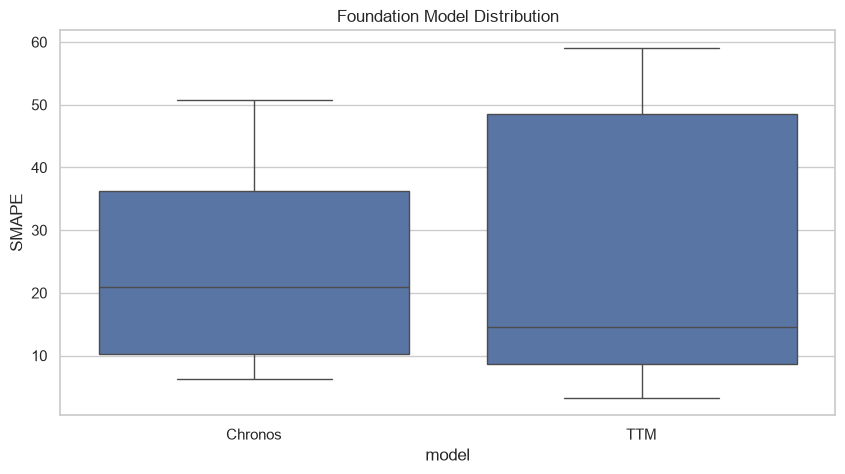

In [17]:
plt.figure(
    figsize=(10,5)
)

sns.boxplot(
    data=foundation_results,
    x="model",
    y="SMAPE"
)

plt.title(
    "Foundation Model Distribution"
)

plt.show()

In [18]:
compare_families = (
    all_results
    .groupby(
        [
            "dataset",
            "family"
        ]
    )["SMAPE"]
    .mean()
    .reset_index()
)

pivot = compare_families.pivot(
    index="dataset",
    columns="family",
    values="SMAPE"
)

pivot

family,Classical,Deep Learning,Foundation,Machine Learning
dataset,,,,
agri_medium,10.043656,199.856499,11.067682,73.087442
agri_small,9.996013,199.886609,11.147433,73.478086
energy_medium,31.574378,57.744152,35.625044,60.024925
energy_small,41.342021,95.754583,36.078800,58.367628
favorita-train_medium,55.636043,52.514096,54.903386,67.434520
favorita-train_small,55.235768,NaN,54.889756,66.060492
favorita-transaction_medium,6.417477,NaN,6.612360,7.254942
favorita-transaction_small,6.536100,NaN,6.867000,7.252185
m4-daily_medium,3.348230,NaN,3.273635,8.691589


In [19]:
all_results.groupby("family").head()

,model,dataset,n_series,n_rows,horizon,runtime_seconds,MAE,RMSE,SMAPE,family
0,Naive,agri_medium,246,15343,5,1.266055,5.904066e+05,3.723966e+06,10.800519,Classical
1,SeasonalNaive,agri_medium,246,15343,5,1.435681,5.904066e+05,3.723966e+06,10.800519,Classical
2,ARIMA,agri_medium,246,15343,5,13.942256,2.144493e+05,6.649463e+05,9.278785,Classical
3,SARIMA,agri_medium,246,15343,5,0.502644,2.043096e+05,6.231367e+05,9.294803,Classical
4,Naive,agri_small,246,14428,5,1.181755,5.904066e+05,3.723966e+06,10.800519,Classical
80,LightGBM,agri_medium,246,15343,5,5.512362,1.345459e+06,1.193758e+07,72.657659,Machine Learning
81,XGBoost,agri_medium,246,15343,5,4.654321,1.286657e+06,1.190936e+07,73.517225,Machine Learning
82,LightGBM,agri_small,246,14428,5,3.158057,1.359613e+06,1.161104e+07,72.991220,Machine Learning
83,XGBoost,agri_small,246,14428,5,5.109045,1.329722e+06,1.176519e+07,73.964951,Machine Learning
84,LightGBM,energy_medium,370,177600,24,23.006917,2.513174e+02,1.244485e+03,59.320120,Machine Learning


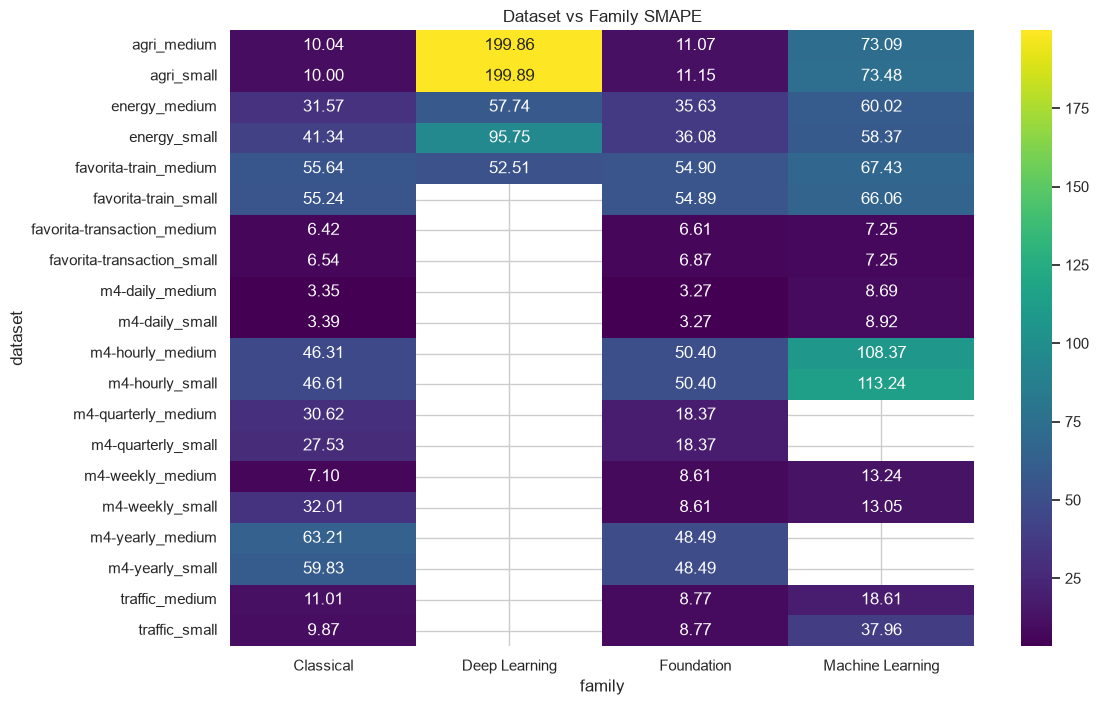

In [20]:
plt.figure(
    figsize=(12,8)
)

sns.heatmap(
    pivot,
    cmap="viridis",
    annot=True,
    fmt=".2f"
)

plt.title(
    "Dataset vs Family SMAPE"
)

plt.show()

In [21]:
runtime = (
    all_results
    .groupby("model")
    ["runtime_seconds"]
    .mean()
    .sort_values()
)

runtime

model
ARIMA              23.893537
SARIMA             57.949001
LightGBM           87.649708
XGBoost           123.407640
TTM               154.365745
SeasonalNaive     564.286723
Naive             564.659496
Chronos          4553.946429
LSTM             6214.706450
Name: runtime_seconds, dtype: float64

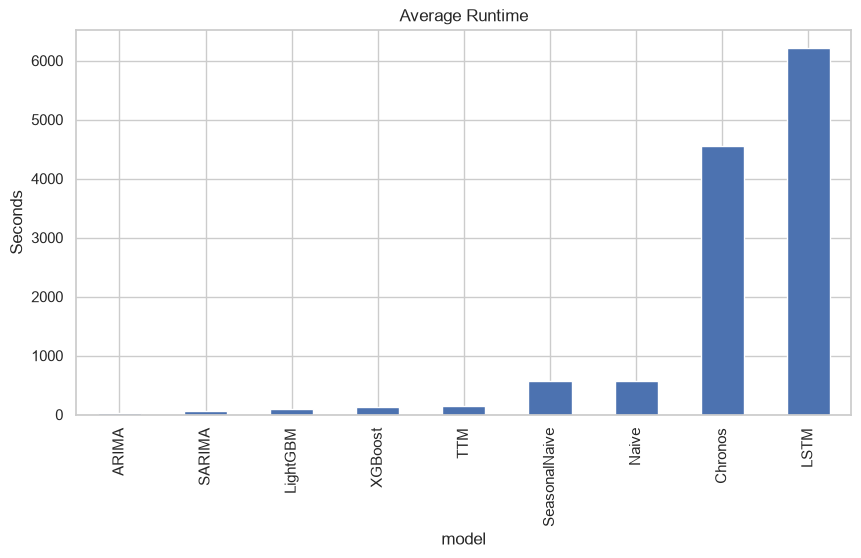

In [22]:
plt.figure(
    figsize=(10,5)
)

runtime.plot(
    kind="bar"
)

plt.ylabel(
    "Seconds"
)

plt.title(
    "Average Runtime"
)

plt.show()

In [23]:
balanced = (
    all_results
    .groupby("model")
    [
        [
            "SMAPE",
            "runtime_seconds"
        ]
    ]
    .mean()
)

balanced["normalized_smape"] = (
    balanced["SMAPE"] /
    balanced["SMAPE"].max()
)

balanced["normalized_runtime"] = (
    balanced["runtime_seconds"] /
    balanced["runtime_seconds"].max()
)

balanced["score"] = (
    balanced["normalized_smape"] +
    balanced["normalized_runtime"]
)

balanced.sort_values(
    "score"
)

,SMAPE,runtime_seconds,normalized_smape,normalized_runtime,score
model,,,,,
ARIMA,24.265442,23.893537,0.200291,0.003845,0.204135
TTM,25.551445,154.365745,0.210905,0.024839,0.235744
SARIMA,34.795985,57.949001,0.287211,0.009324,0.296536
Naive,25.551445,564.659496,0.210905,0.090859,0.301764
SeasonalNaive,26.912169,564.286723,0.222137,0.090799,0.312936
LightGBM,45.345277,87.649708,0.374287,0.014104,0.388390
XGBoost,46.534258,123.407640,0.384101,0.019857,0.403958
Chronos,24.899302,4553.946429,0.205523,0.732769,0.938292
LSTM,121.151188,6214.706450,1.000000,1.000000,2.000000


In [24]:
favorita_cov = pd.read_csv(
    RESULTS_FOLDER /
    "favorita_covariate_model_results.csv"
)

favorita_cov

,Model,MAE
0,LSTM,3.100792
1,XGBoost,3.126215
2,LightGBM,3.135344
3,NHITS,4.055415


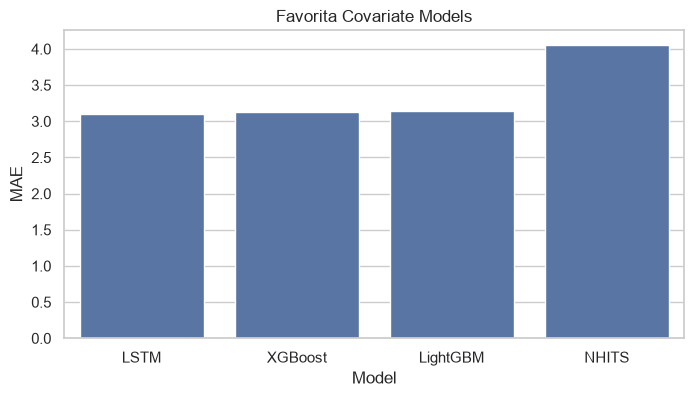

In [25]:
plt.figure(
    figsize=(8,4)
)

sns.barplot(
    data=favorita_cov,
    x="Model",
    y="MAE"
)

plt.title(
    "Favorita Covariate Models"
)

plt.show()

In [26]:
summary = pd.DataFrame(
    {
        "Finding":[
            "Best Overall Model",
            "Best Foundation Model",
            "Fastest Model",
            "Best Family"
        ],
        "Value":[
            overall.index[0],
            foundation_results
            .groupby("model")["MAE"]
            .mean()
            .idxmin(),
            runtime.idxmin(),
            family_results["MAE"]
            .idxmin()
        ]
    }
)

summary

,Finding,Value
0,Best Overall Model,ARIMA
1,Best Foundation Model,TTM
2,Fastest Model,ARIMA
3,Best Family,Foundation


In [27]:
overall.to_csv(
    RESULTS_FOLDER /
    "analysis_overall.csv"
)

avg_rank.to_csv(
    RESULTS_FOLDER /
    "analysis_average_rank.csv"
)

family_results.to_csv(
    RESULTS_FOLDER /
    "analysis_family_summary.csv"
)

summary.to_csv(
    RESULTS_FOLDER /
    "analysis_key_findings.csv"
)

print("Analysis exports saved")

Analysis exports saved


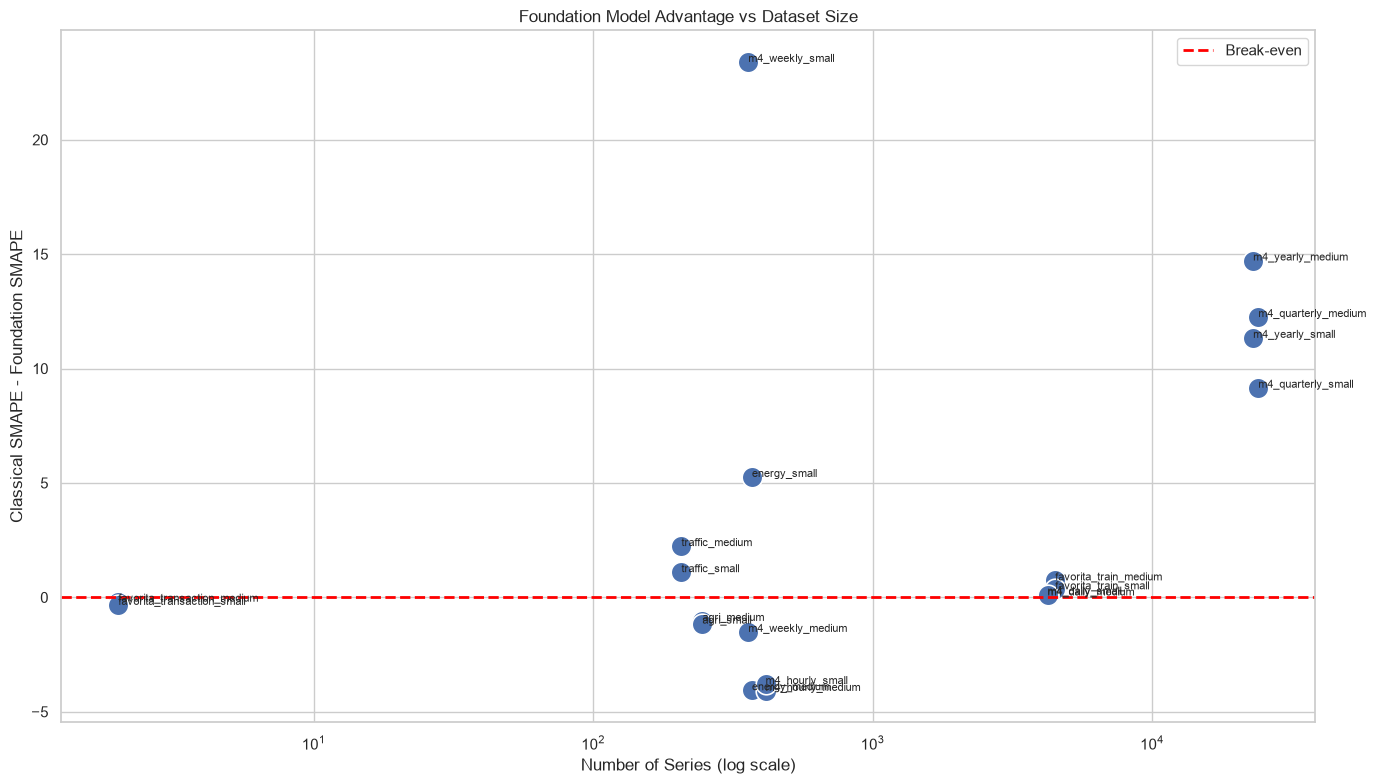

In [28]:
import pandas as pd

df = pd.DataFrame({

    "dataset":[
        "agri_medium",
        "agri_small",
        "energy_medium",
        "energy_small",
        "favorita_train_medium",
        "favorita_train_small",
        "favorita_transaction_medium",
        "favorita_transaction_small",
        "m4_daily_medium",
        "m4_daily_small",
        "m4_hourly_medium",
        "m4_hourly_small",
        "m4_quarterly_medium",
        "m4_quarterly_small",
        "m4_weekly_medium",
        "m4_weekly_small",
        "m4_yearly_medium",
        "m4_yearly_small",
        "traffic_medium",
        "traffic_small"
    ],

    "n_series":[
        246,
        246,
        370,
        370,
        4504,
        4504,
        2,
        2,
        4227,
        4227,
        414,
        414,
        24000,
        24000,
        359,
        359,
        23000,
        23000,
        207,
        207
    ],

    "classical":[
        10.04,
        10.00,
        31.57,
        41.34,
        55.64,
        55.24,
        6.42,
        6.54,
        3.35,
        3.39,
        46.31,
        46.61,
        30.62,
        27.53,
        7.10,
        32.01,
        63.21,
        59.83,
        11.01,
        9.87
    ],

    "foundation":[
        11.07,
        11.15,
        35.63,
        36.08,
        54.90,
        54.89,
        6.61,
        6.87,
        3.27,
        3.27,
        50.40,
        50.40,
        18.37,
        18.37,
        8.61,
        8.61,
        48.49,
        48.49,
        8.77,
        8.77
    ]

})

df["advantage"] = df["classical"] - df["foundation"]

plt.figure(figsize=(14,8))

sns.scatterplot(
    data=df,
    x="n_series",
    y="advantage",
    s=220
)

for _, row in df.iterrows():

    plt.annotate(
        row["dataset"],
        (row["n_series"], row["advantage"]),
        fontsize=8
    )

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Break-even"
)

plt.xscale("log")

plt.ylabel(
    "Classical SMAPE - Foundation SMAPE"
)

plt.xlabel(
    "Number of Series (log scale)"
)

plt.title(
    "Foundation Model Advantage vs Dataset Size"
)

plt.legend()

plt.tight_layout()
plt.show()

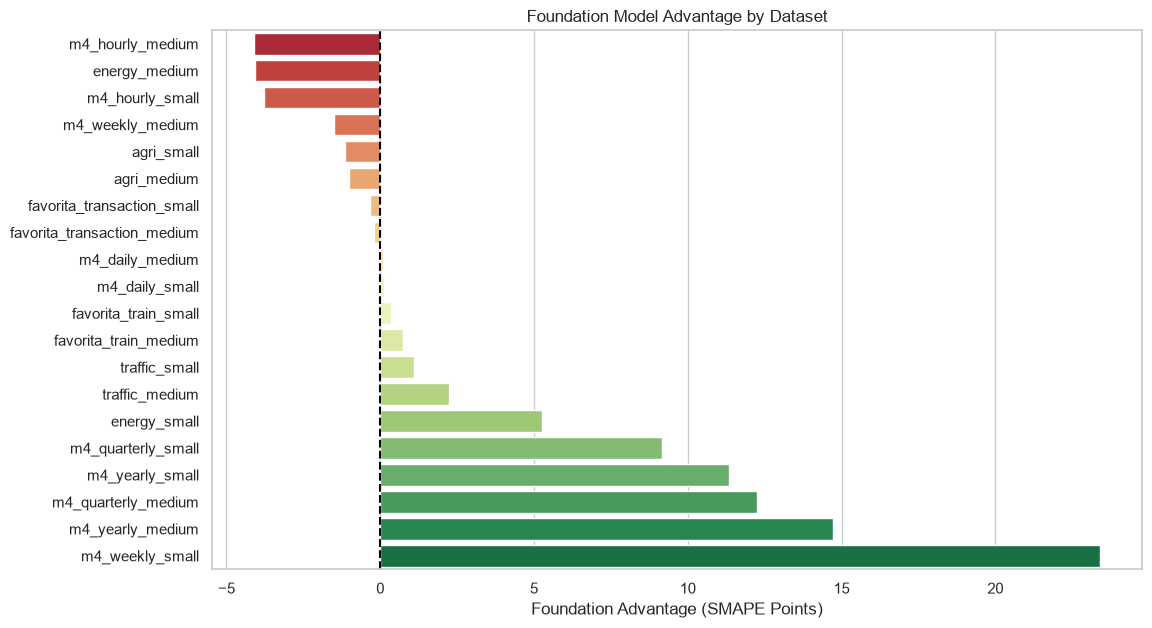

In [29]:
plot_df = df.sort_values(
    "advantage"
)

plt.figure(figsize=(12,7))

sns.barplot(
    data=plot_df,
    x="advantage",
    y="dataset",
    palette="RdYlGn"
)

plt.axvline(
    0,
    color="black",
    linestyle="--"
)

plt.xlabel(
    "Foundation Advantage (SMAPE Points)"
)

plt.ylabel("")

plt.title(
    "Foundation Model Advantage by Dataset"
)

plt.show()

In [30]:
df

,dataset,n_series,classical,foundation,advantage
0,agri_medium,246,10.04,11.07,-1.03
1,agri_small,246,10.00,11.15,-1.15
2,energy_medium,370,31.57,35.63,-4.06
3,energy_small,370,41.34,36.08,5.26
4,favorita_train_medium,4504,55.64,54.90,0.74
5,favorita_train_small,4504,55.24,54.89,0.35
6,favorita_transaction_medium,2,6.42,6.61,-0.19
7,favorita_transaction_small,2,6.54,6.87,-0.33
8,m4_daily_medium,4227,3.35,3.27,0.08
9,m4_daily_small,4227,3.39,3.27,0.12
